# Qwen3.5-9B 벤치마크 표 (A100 Colab 원시 데이터)

GPU를 쓰지 않습니다. 2026-10-17 Colab A100-SXM4-40GB에서 잰 **원시 JSON 3개**를 읽어서
벤치마크 표와 그래프를 만듭니다. 데이터는 `notebooks/assets/qwen3_5_9b_a100_20261017/`에 들어 있습니다.

| 파일 | 만든 스크립트 | 내용 |
|---|---|---|
| `prefill.json` | `scripts/bench_qwen3_5.py` | 1024-token prefill, 128-token decode. torch vs FLA × dynamic vs static cache, HF 기본값 |
| `decode.json` | `scripts/bench_qwen3_5_decode.py` | decode 모드별(sliced-eager / eager / compile / compile-reduce-overhead / cudagraph) ms/token과 수치 차이 |
| `decode_modes.json` | `scripts/validate_qwen3_5_decode_modes.py` | 9개 프롬프트에서 HF 대비 KL·top-1·생성 불일치 |

표와 그래프의 숫자는 모두 위 파일에서 계산됩니다(§4의 주의사항 글에 인용한 값만 예외).

## §0. 데이터 읽기와 출처

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

DATA = Path("assets/qwen3_5_9b_a100_20261017")
if not DATA.exists():  # 저장소 루트에서 연 경우
    DATA = Path("notebooks") / DATA

prefill_raw = json.loads((DATA / "prefill.json").read_text())
decode_raw = json.loads((DATA / "decode.json").read_text())
modes_raw = json.loads((DATA / "decode_modes.json").read_text())


def md_table(header, rows, align=None):
    """Markdown 표로 렌더링한다. pandas 없이 쓰려고 직접 만든다."""
    align = align or ["l"] + ["r"] * (len(header) - 1)
    rule = ["---:" if a == "r" else ":---" for a in align]
    lines = ["| " + " | ".join(header) + " |", "| " + " | ".join(rule) + " |"]
    lines += ["| " + " | ".join(str(c) for c in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


for name in ("prefill.json", "decode.json", "decode_modes.json"):
    print(f"{name:18s} sha256 {hashlib.sha256((DATA / name).read_bytes()).hexdigest()[:16]}…")
print()
print("device :", prefill_raw["device"])
print("torch  :", prefill_raw["torch"])
a = prefill_raw["args"]
print(f"model  : {a['repo']} ({a['dtype']}), batch {a['batch']}, prompt {a['prompt_tokens']} → new {a['new_tokens']} tokens")

prefill.json       sha256 d7d58f175d2f582b…
decode.json        sha256 c1465dd2e14201dd…
decode_modes.json  sha256 f8d92451469ca974…

device : NVIDIA A100-SXM4-40GB
torch  : 2.11.0+cu130
model  : Qwen/Qwen3.5-9B (bfloat16), batch 1, prompt 1024 → new 128 tokens


## §1. Prefill / decode (표 1)

`bench_qwen3_5.py`의 측정 방식:
- **prefill**: 1024 token을 한 번에 처리하는 시간, warm-up 뒤 3회 평균.
- **decode**: 128 token을 한 개씩 생성하는 구간을 3번 돌려 **최솟값**.
- **HF 기본값**의 decode는 `generate(128)`과 `generate(1)`의 시간 차를 127로 나눈 값입니다(직접 잰 값이 아니라 차분).
- `greedy16`: 처음 16 token이 `torch / dynamic` 결과와 같은지.

In [2]:
rows = prefill_raw["rows"]
name = lambda r: r["kernels"] if r["kernels"] == "hf-default" else f"{r['kernels']} / {'static' if r['static_cache'] else 'dynamic'}"
base = next(r for r in rows if r["kernels"] == "torch" and not r["static_cache"])
hf = next(r for r in rows if r["kernels"] == "hf-default")

md_table(
    ["구현", "prefill ms", "prefill tok/s", "vs torch", "vs HF", "decode ms/tok", "decode tok/s", "peak GiB", "greedy16"],
    [[name(r), f"{r['prefill_ms']:.1f}", f"{r['prefill_tok_per_s']:,.0f}",
      f"{base['prefill_ms'] / r['prefill_ms']:.2f}×", f"{hf['prefill_ms'] / r['prefill_ms']:.2f}×",
      f"{r['decode_ms_per_token']:.1f}", f"{r['decode_tok_per_s']:.1f}",
      f"{r['peak_mem_gib']:.2f}" if "peak_mem_gib" in r else "–",
      {True: "✓", False: "✗", None: "–"}[r.get("greedy16_matches_torch_dynamic")]] for r in rows])
print("vs torch / vs HF: prefill 시간 비 (1보다 크면 그 구현이 빠름)")

| 구현 | prefill ms | prefill tok/s | vs torch | vs HF | decode ms/tok | decode tok/s | peak GiB | greedy16 |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| torch / dynamic | 182.3 | 5,616 | 1.00× | 0.60× | 59.4 | 16.8 | 17.27 | ✓ |
| torch / static | 183.2 | 5,591 | 1.00× | 0.59× | 59.6 | 16.8 | 17.26 | ✓ |
| fla / dynamic | 100.2 | 10,224 | 1.82× | 1.08× | 63.4 | 15.8 | 17.49 | ✓ |
| fla / static | 100.6 | 10,174 | 1.81× | 1.08× | 63.9 | 15.7 | 17.26 | ✓ |
| hf-default | 108.6 | 9,432 | 1.68× | 1.00× | 61.7 | 16.2 | – | – |

vs torch / vs HF: prefill 시간 비 (1보다 크면 그 구현이 빠름)


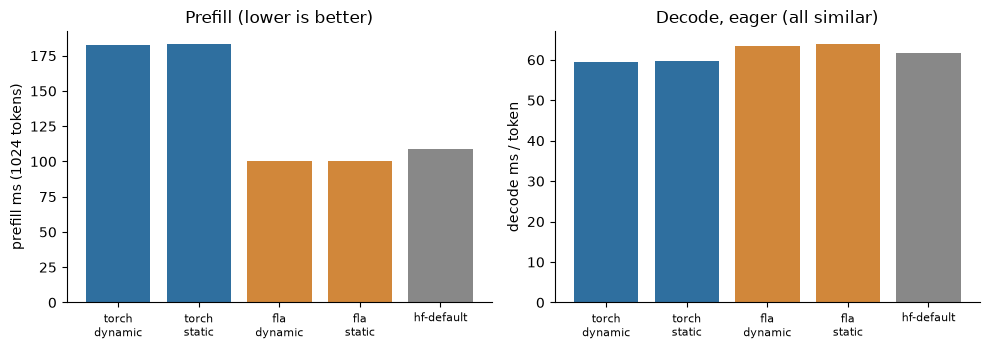

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
labels = [name(r).replace(" / ", "\n") for r in rows]
colors = ["#2f6f9f" if r["kernels"] == "torch" else "#d1873a" if r["kernels"] == "fla" else "#888888" for r in rows]
ax1.bar(labels, [r["prefill_ms"] for r in rows], color=colors)
ax1.set_ylabel("prefill ms (1024 tokens)"); ax1.set_title("Prefill (lower is better)")
ax2.bar(labels, [r["decode_ms_per_token"] for r in rows], color=colors)
ax2.set_ylabel("decode ms / token"); ax2.set_title("Decode, eager (all similar)")
for ax in (ax1, ax2):
    ax.tick_params(axis="x", labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## §2. Decode 모드 (표 2)

`bench_qwen3_5_decode.py`: 같은 prefill 뒤에 token을 하나씩 이어 붙이며 **warm-up 뒤 steady-state ms/token**
(여러 step 평균)을 잽니다. compile / CUDA graph 준비 시간(`prepare_s`, `first_step_s`)은 따로 기록되어 ms/token에 들어가지 않습니다.
수치는 sliced-eager와 **같은 token을 먹였을 때**의 logits 차이입니다.

모드 설명: `sliced-eager`는 기존 경로(캐시를 매 step 잘라 씀), 나머지는 고정 shape 경로입니다.
`fla-delta`는 FLA 커널을 delta-rule에만 쓰고 conv는 torch로 둔 구성입니다.

In [4]:
drows = decode_raw["rows"]
MODE_ORDER = ["sliced-eager", "eager", "compile", "compile-reduce-overhead", "cudagraph"]
by = {(r["kernels"], r["mode"]): r for r in drows}
hf_ms = hf["decode_ms_per_token"]

out = []
for kernels in ("torch", "fla-delta"):
    sliced = by[(kernels, "sliced-eager")]["ms_per_token"]
    for mode in MODE_ORDER:
        r = by[(kernels, mode)]
        out.append([kernels, mode, f"{r['ms_per_token']:.2f}", f"{1000 / r['ms_per_token']:.1f}",
                    f"{sliced / r['ms_per_token']:.2f}×", f"{hf_ms / r['ms_per_token']:.2f}×",
                    f"{r['first_step_s']:.1f}", f"{r['prepare_s']:.2f}",
                    f"{r['argmax_agreement']:.3f}", f"{r['logits_max_abs_diff']:.3f}",
                    r.get("graph_breaks", "–")])
md_table(["kernels", "mode", "ms/tok", "tok/s", "vs 자기 sliced-eager", "vs HF 기본", "첫 step s", "prepare s",
          "argmax 일치", "max|Δlogit|", "graph breaks"], out, ["l", "l"] + ["r"] * 9)
print(f"HF 기본 decode 기준값 {hf_ms:.1f} ms/tok (표 1)")

| kernels | mode | ms/tok | tok/s | vs 자기 sliced-eager | vs HF 기본 | 첫 step s | prepare s | argmax 일치 | max|Δlogit| | graph breaks |
| :--- | :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| torch | sliced-eager | 61.53 | 16.3 | 1.00× | 1.00× | 0.1 | 0.00 | 1.000 | 0.000 | – |
| torch | eager | 61.72 | 16.2 | 1.00× | 1.00× | 0.1 | 0.00 | 1.000 | 0.188 | – |
| torch | compile | 16.98 | 58.9 | 3.62× | 3.63× | 7.7 | 0.00 | 1.000 | 0.156 | 0 |
| torch | compile-reduce-overhead | 16.09 | 62.2 | 3.82× | 3.84× | 8.3 | 0.00 | 1.000 | 0.156 | 0 |
| torch | cudagraph | 19.89 | 50.3 | 3.09× | 3.10× | 0.0 | 0.26 | 1.000 | 0.188 | – |
| fla-delta | sliced-eager | 55.02 | 18.2 | 1.00× | 1.12× | 0.1 | 0.00 | 1.000 | 0.000 | – |
| fla-delta | eager | 56.02 | 17.8 | 0.98× | 1.10× | 0.1 | 0.00 | 1.000 | 0.279 | – |
| fla-delta | compile | 17.02 | 58.7 | 3.23× | 3.63× | 21.7 | 0.00 | 0.979 | 0.188 | 0 |
| fla-delta | compile-reduce-overhead | 15.08 | 66.3 | 3.65× | 4.09× | 21.8 | 0.00 | 0.979 | 0.188 | 0 |
| fla-delta | cudagraph | 18.26 | 54.8 | 3.01× | 3.38× | 0.0 | 0.23 | 1.000 | 0.279 | – |

HF 기본 decode 기준값 61.7 ms/tok (표 1)


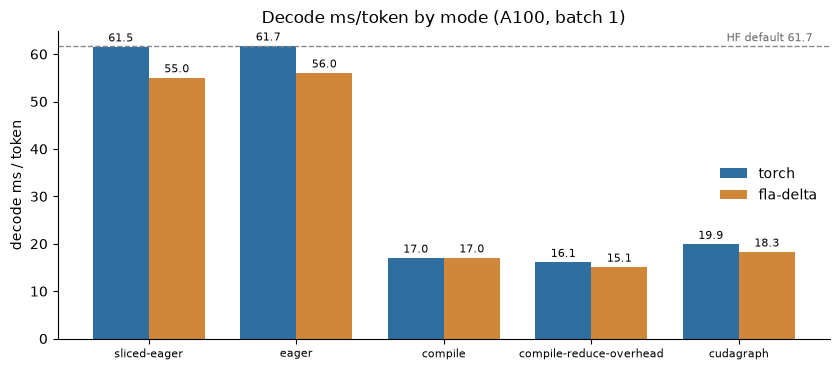

In [5]:
import numpy as np

fig, ax = plt.subplots(figsize=(8.5, 3.8))
x = np.arange(len(MODE_ORDER)); w = 0.38
for i, (kernels, color) in enumerate((("torch", "#2f6f9f"), ("fla-delta", "#d1873a"))):
    vals = [by[(kernels, m)]["ms_per_token"] for m in MODE_ORDER]
    bars = ax.bar(x + (i - 0.5) * w, vals, w, label=kernels, color=color)
    ax.bar_label(bars, fmt="%.1f", fontsize=8, padding=2)
ax.axhline(hf_ms, ls="--", color="#888", lw=1); ax.text(len(MODE_ORDER) - 0.5, hf_ms + 1, f"HF default {hf_ms:.1f}", ha="right", fontsize=8, color="#666")
ax.set_xticks(x, MODE_ORDER, fontsize=8); ax.set_ylabel("decode ms / token"); ax.set_title("Decode ms/token by mode (A100, batch 1)")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

### 파생 지표 — 메모리 대역폭 한계

batch 1 decode는 token마다 가중치 전체를 HBM에서 한 번 읽습니다. 가중치 크기를 peak 메모리로 근사하고
A100-SXM4-40GB의 HBM 대역폭(1555 GB/s, spec sheet 값)으로 나누면 ms/token의 **어림 하한**이 됩니다.
peak에는 활성값·캐시가 조금 섞여 있으므로 하한은 약간 높게 잡힌 값입니다.

In [6]:
HBM_GBPS = 1555
peak_gib = next(r["peak_mem_gib"] for r in rows if r["kernels"] == "torch" and r["static_cache"])
floor_ms = peak_gib * 2**30 / (HBM_GBPS * 1e9) * 1e3
print(f"읽는 바이트 ≈ peak {peak_gib:.2f} GiB → 하한 ≈ {floor_ms:.1f} ms/token ({1000 / floor_ms:.0f} tok/s)\n")
md_table(["구성", "ms/tok", "하한 대비 달성률", "하한과의 격차 ms"],
         [[f"{k}:{m}", f"{by[(k, m)]['ms_per_token']:.2f}", f"{floor_ms / by[(k, m)]['ms_per_token']:.0%}",
           f"{by[(k, m)]['ms_per_token'] - floor_ms:.1f}"]
          for k in ("torch", "fla-delta") for m in ("sliced-eager", "compile-reduce-overhead", "cudagraph")])

읽는 바이트 ≈ peak 17.26 GiB → 하한 ≈ 11.9 ms/token (84 tok/s)



| 구성 | ms/tok | 하한 대비 달성률 | 하한과의 격차 ms |
| :--- | ---: | ---: | ---: |
| torch:sliced-eager | 61.53 | 19% | 49.6 |
| torch:compile-reduce-overhead | 16.09 | 74% | 4.2 |
| torch:cudagraph | 19.89 | 60% | 8.0 |
| fla-delta:sliced-eager | 55.02 | 22% | 43.1 |
| fla-delta:compile-reduce-overhead | 15.08 | 79% | 3.2 |
| fla-delta:cudagraph | 18.26 | 65% | 6.3 |

## §3. HF 대비 정확도 (표 3)

9개 프롬프트로 `transformers` 구현과 비교한 결과를 (kernels, mode)별로 접었습니다.

- **mean KL / min top-1**: 프롬프트 마지막 최대 32 위치의 logits 분포 차이. KL은 프롬프트별 값의 단순 평균이고, token이 1개인 `hello`는 제외됩니다. 짧은 프롬프트는 위치 수가 적습니다.
- **teacher-forced 불일치**: HF가 만든 token을 먹였을 때 다음 token이 HF와 다른 step. HF의 top-1/top-2 margin이
  0.5 이하면 near-tie(bf16 반올림으로 뒤집힐 수 있음), 넘으면 strong. **strong이 0이면 불일치가 전부 HF의 1·2위 logit이 거의 같은 자리에서 갈린 것**이라는 뜻입니다.
- **free-run 일치**: 192 token을 자유 생성해서 HF와 끝까지 같은 프롬프트 수. 한 번 갈라지면 뒤가 계속 달라지므로 엄격한 지표입니다.

In [7]:
PROMPTS = [r["prompt"] for r in modes_raw["rows"] if r["kernels"] == "torch" and r["mode"] == "sliced-eager" and not r.get("summary")]
per = {}
for r in modes_raw["rows"]:
    key = (r["kernels"], r["mode"])
    d = per.setdefault(key, {"rows": [], "summary": None})
    (d.__setitem__("summary", r) if r.get("summary") else d["rows"].append(r))

out = []
for (kernels, mode), d in per.items():
    s, rs = d["summary"], d["rows"]
    if "error" in s:
        out.append([kernels, mode, "–", "–", "–", "–", "–", "–", f"실패: {s['error'].splitlines()[0][:44]}…"])
        continue
    kl = [r["decode_kl_vs_hf"] for r in rs if "decode_kl_vs_hf" in r]
    top1 = [r["decode_top1_vs_hf"] for r in rs if "decode_top1_vs_hf" in r]
    strong = sum(r["tf_mismatch_strong"] for r in rs)
    near = sum(r["tf_mismatch_near_tie"] for r in rs)
    exact = sum(r["gen_first_mismatch"] is None for r in rs)
    out.append([kernels, mode, f"{sum(kl) / len(kl):.2e}", f"{min(top1):.3f}", strong, near, f"{exact}/{len(rs)}",
                s.get("dynamo_unique_graphs") or "–", ""])
md_table(["kernels", "mode", "mean KL", "min top-1", "strong", "near-tie", "free-run 일치", "graphs", "비고"], out,
         ["l", "l"] + ["r"] * 6 + ["l"])
print("strong 합계:", sum(row[4] for row in out if isinstance(row[4], int)))

| kernels | mode | mean KL | min top-1 | strong | near-tie | free-run 일치 | graphs | 비고 |
| :--- | :--- | ---: | ---: | ---: | ---: | ---: | ---: | :--- |
| torch | sliced-eager | 4.70e-04 | 1.000 | 0 | 7 | 5/9 | – |  |
| torch | eager | 4.58e-04 | 1.000 | 0 | 13 | 4/9 | – |  |
| torch | compile | 4.00e-04 | 0.968 | 0 | 12 | 4/9 | 1 |  |
| torch | compile-reduce-overhead | 4.00e-04 | 0.968 | 0 | 12 | 4/9 | 1 |  |
| torch | cudagraph | 4.58e-04 | 1.000 | 0 | 13 | 4/9 | – |  |
| fla-delta | sliced-eager | 4.36e-04 | 0.947 | 0 | 9 | 4/9 | – |  |
| fla-delta | cudagraph | 3.95e-04 | 0.947 | 0 | 7 | 5/9 | – |  |
| fla-delta | compile-reduce-overhead | 4.05e-04 | 0.938 | 0 | 9 | 4/9 | 1 |  |
| fla | sliced-eager | 4.20e-04 | 0.968 | 0 | 8 | 5/9 | – |  |
| fla | cudagraph | 4.33e-04 | 1.000 | 0 | 12 | 3/9 | – |  |
| fla | compile-reduce-overhead | – | – | – | – | – | – | 실패: Unsupported: Skip calling `torch.compiler.di… |

strong 합계: 0


### 프롬프트별 KL

KL이 프롬프트 길이에 얼마나 민감한지 봅니다(`decode_kl_vs_hf`, 낮을수록 HF와 가깝습니다).
`hello`는 token이 1개라 decode 구간 지표가 없어 `–`입니다.

In [8]:
configs = [k for k, d in per.items() if "error" not in d["summary"]]
cell_of = lambda cfg, p: next((r for r in per[cfg]["rows"] if r["prompt"] == p), {})
md_table(["prompt (tokens)"] + [f"{k}:{m}" for k, m in configs],
         [[f"{p} ({cell_of(configs[0], p)['tokens']})"] +
          [f"{cell_of(c, p)['decode_kl_vs_hf']:.1e}" if "decode_kl_vs_hf" in cell_of(c, p) else "–" for c in configs]
          for p in PROMPTS])

| prompt (tokens) | torch:sliced-eager | torch:eager | torch:compile | torch:compile-reduce-overhead | torch:cudagraph | fla-delta:sliced-eager | fla-delta:cudagraph | fla-delta:compile-reduce-overhead | fla:sliced-eager | fla:cudagraph |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| short (5) | 5.5e-04 | 5.5e-04 | 2.7e-04 | 2.7e-04 | 5.5e-04 | 3.9e-04 | 3.9e-04 | 2.1e-04 | 6.5e-04 | 6.5e-04 |
| hello (1) | – | – | – | – | – | – | – | – | – | – |
| korean (20) | 4.5e-04 | 4.5e-04 | 6.0e-04 | 6.0e-04 | 4.5e-04 | 4.4e-04 | 3.4e-04 | 5.4e-04 | 4.5e-04 | 4.5e-04 |
| math (43) | 5.5e-04 | 7.5e-04 | 6.0e-04 | 6.0e-04 | 7.5e-04 | 4.8e-04 | 5.1e-04 | 6.3e-04 | 6.0e-04 | 5.6e-04 |
| chat (23) | 3.0e-04 | 3.5e-04 | 2.3e-04 | 2.3e-04 | 3.5e-04 | 3.5e-04 | 3.3e-04 | 2.8e-04 | 3.4e-04 | 3.5e-04 |
| chat_long (32) | 6.2e-04 | 6.0e-04 | 5.8e-04 | 5.8e-04 | 6.0e-04 | 6.5e-04 | 5.5e-04 | 7.7e-04 | 6.3e-04 | 6.8e-04 |
| prose_1k (1057) | 2.0e-04 | 2.0e-04 | 2.0e-04 | 2.0e-04 | 2.0e-04 | 2.3e-04 | 2.0e-04 | 2.2e-04 | 8.1e-05 | 8.7e-05 |
| code_1k (1000) | 2.2e-04 | 2.2e-04 | 1.0e-04 | 1.0e-04 | 2.2e-04 | 3.5e-04 | 2.7e-04 | 1.8e-04 | 1.9e-04 | 1.6e-04 |
| code_1_5k (1500) | 8.6e-04 | 5.4e-04 | 6.1e-04 | 6.1e-04 | 5.4e-04 | 6.0e-04 | 5.6e-04 | 4.0e-04 | 4.2e-04 | 5.1e-04 |

### 실패한 설정

In [9]:
for (kernels, mode), d in per.items():
    if "error" in d["summary"]:
        print(f"{kernels}:{mode}\n")
        print(d["summary"]["error"][:400])

fla:compile-reduce-overhead

Unsupported: Skip calling `torch.compiler.disable()`d function
  Explanation: Skip calling function `<function causal_conv1d_fwd at 0x7c1e8ef0a700>` since it was wrapped with `torch.compiler.disable` (reason: None)
  Hint: Remove the `torch.compiler.disable` call

  Developer debug context: <function causal_conv1d_fwd at 0x7c1e8ef0a700>

 For more details about this graph break, please visit: http


## §4. 읽을 때 주의할 점

1. **표 1과 표 2의 decode 숫자는 같은 구성이어도 달라집니다.** 표 1의 `torch / dynamic`은 59.4 ms, 표 2의 `torch:sliced-eager`는 61.5 ms 입니다.
   스크립트·캐시 구현·측정 구간(최솟값 vs 평균)이 달라서 생기는 약 3–4%의 차이이고, 두 표를 섞어 계산하지 마세요.
   표 2의 "vs HF 기본"은 표 2의 값을 표 1의 HF 값으로 나눈 것이므로 방법이 다른 숫자끼리의 비교입니다.
2. **측정은 1회 실행**입니다(반복 간 분산은 저장되어 있지 않습니다). 몇 % 차이는 해석하지 마세요.
3. **batch 1, 1024 token 컨텍스트, 랜덤 입력 token**의 결과입니다. 생성 품질 평가가 아닙니다.
4. 표 1의 prefill은 FLA 커널 쪽이 약 1.8배 빠르지만 decode는 오히려 소폭 느립니다(63 vs 59 ms).
   decode는 launch 오버헤드가 지배적이라 커널 선택보다 고정 shape + CUDA graph 여부가 훨씬 큰 영향을 줍니다(표 2).
5. 정확도에서 `fla-delta`/`fla`의 top-1이 0.94~0.97까지 내려가는 것은 짧은 프롬프트(`korean`·`math`·`chat_long`)에서
   비교 위치가 19~32개뿐이라 한두 token이 뒤집힌 결과입니다. 실패한 설정을 뺀 모든 설정에서 strong 불일치는 0입니다(표 3).